# DIP Assignment 1 — Problem 5: Green screen keying and compositing

**Name:** Kushal Mukherjee &nbsp;&nbsp; **Roll number:** 2025201072

Footage: `images/p5/video1.mp4`, 1920x1080 at 25 fps, 30.4 s. The 48 frames used here were
extracted to `images/p5/frames/` at 1280x720 with

    python code/assets/ingest_greenscreen.py images/p5/video1.mp4 --frames 48 --report

Background plate: `images/p5/background.png`, 3400x1661, which is 2.66x the frame width so it
can pan across the sequence.

In [1]:
import time
import platform
import subprocess

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

ROOT = Path.cwd()

print("CPU    :", subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip())
print("RAM    :", round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 1e9), "GB")
print("OS     :", platform.platform())
print("Python :", platform.python_version())
print("NumPy  :", np.__version__)

CPU    : Apple M4
RAM    : 17 GB
OS     : macOS-15.7.7-arm64-arm-64bit-Mach-O
Python : 3.13.9
NumPy  : 2.4.1


**Say which clip you chose and why it meets the requirement (hair, motion blur or translucent
material, not AI-generated, not watermarked). Credit the source.**

I used `video1.mp4`, 1920x1080 at 25 fps, and extracted 48 frames at 1280x720, which is above
the 720p requirement. It is not AI-generated and carries no watermark.

The reason I chose this one is that it is **raw footage of a real green screen**, not a clip
that has already been keyed. That matters, and I only realised it after trying two others
first. In the clips I rejected, 76% of every frame was one single RGB value, the backing was
perfectly uniform, and the backing luma had a standard deviation of about 0.4. That is
impossible for real footage. Those clips had been keyed by the publisher and re-composited
onto a flat digital green, which removes exactly the thing 5.1 is about.

This clip measures completely differently:

| | rejected clip | this clip |
|---|---|---|
| most common single colour | 76.5% of frame | 0.8% |
| backing luma std | 0.34 | 14.12 |
| backing chroma spread | 0.63 | 1.61 |
| fractional alpha | 0.33% | 1.15% |

The backing luma runs from about 110 in the bottom-left corner to 150 in the top-right, so it
is genuinely unevenly lit, and the noise and lighting falloff are real.

It also meets the soft-edge requirement. The subject has loose hair with wispy strands at the
crown, and there is a hand moving through the frame, so there is motion as well. Measured,
1.15% of pixels come out with alpha strictly between 0 and 1, more than three times what the
rejected clip gave. Without that, 5.2 would collapse, because a hard threshold would match a
soft matte exactly.

In [2]:
FRAME_DIR = ROOT / "images/p5/frames"
BG_PATH = ROOT / "images/p5/background.png"

frame_files = sorted(FRAME_DIR.glob("*.png"))
if not frame_files:
    raise FileNotFoundError(f"No frames in {FRAME_DIR} -- see the note at the top of this notebook.")

frames = [np.asarray(Image.open(f).convert("RGB")) for f in frame_files]
background = np.asarray(Image.open(BG_PATH).convert("RGB"))

print(f"frames     : {len(frames)} x {frames[0].shape}")
print(f"background : {background.shape}")
print(f"pan room   : background is {background.shape[1] / frames[0].shape[1]:.2f}x the frame width")

frame = frames[len(frames) // 2]        # the frame used for all single-frame figures

frames     : 48 x (720, 1280, 3)
background : (1661, 3400, 3)
pan room   : background is 2.66x the frame width


In [3]:
# evidence that this is raw footage rather than a clip that was keyed by the publisher
f = frame.astype(np.float64)
luma = 0.299 * f[..., 0] + 0.587 * f[..., 1] + 0.114 * f[..., 2]
cb = -0.168736 * f[..., 0] - 0.331264 * f[..., 1] + 0.5 * f[..., 2] + 128.0
cr = 0.5 * f[..., 0] - 0.418688 * f[..., 1] - 0.081312 * f[..., 2] + 128.0

corner = (np.median(cb[:24, :24]), np.median(cr[:24, :24]))
dist = np.hypot(cb - corner[0], cr - corner[1])
backing = dist < 10

vals, counts = np.unique(frame.reshape(-1, 3), axis=0, return_counts=True)

print(f"most common single colour : {counts.max() / luma.size:.1%} of the frame")
print(f"distinct colours          : {len(vals)}")
print(f"backing luma  mean / std  : {luma[backing].mean():.1f} / {luma[backing].std():.2f}")
print(f"backing chroma spread     : {dist[backing].std():.2f}")

print("\nbacking luma by corner (this is the uneven lighting):")
for name, sl in [("top-left", (np.s_[:80], np.s_[:80])),
                 ("top-right", (np.s_[:80], np.s_[-80:])),
                 ("bottom-left", (np.s_[-80:], np.s_[:80])),
                 ("bottom-right", (np.s_[-80:], np.s_[-80:]))]:
    m = backing[sl]
    if m.any():
        print(f"  {name:13s} {luma[sl][m].mean():6.1f}")

most common single colour : 0.8% of the frame
distinct colours          : 139429
backing luma  mean / std  : 144.0 / 14.12
backing chroma spread     : 1.61

backing luma by corner (this is the uneven lighting):
  top-left       145.5
  top-right      149.8
  bottom-left    110.3
  bottom-right   116.1


## 5.1 — Naive key

In [4]:
def to_ycbcr(rgb):
    """BT.601 conversion."""
    f = rgb.astype(np.float64)
    y = 0.299 * f[..., 0] + 0.587 * f[..., 1] + 0.114 * f[..., 2]
    cb = -0.168736 * f[..., 0] - 0.331264 * f[..., 1] + 0.5 * f[..., 2] + 128.0
    cr = 0.5 * f[..., 0] - 0.418688 * f[..., 1] - 0.081312 * f[..., 2] + 128.0
    return np.stack([y, cb, cr], axis=-1)


def key_naive_rgb(rgb, thresh=60):
    """Green dominance in raw RGB. alpha = 1 keeps the pixel."""
    f = rgb.astype(np.float64)
    dominance = f[..., 1] - np.maximum(f[..., 0], f[..., 2])
    return (dominance < thresh).astype(np.float64)


def estimate_key_colour(rgb, border=24):
    """Backing chroma, estimated from the frame border. Nothing is hard-coded."""
    ycc = to_ycbcr(rgb)
    edge = np.concatenate([ycc[:border].reshape(-1, 3), ycc[-border:].reshape(-1, 3),
                           ycc[:, :border].reshape(-1, 3), ycc[:, -border:].reshape(-1, 3)])
    return np.median(edge[:, 1]), np.median(edge[:, 2])


def chroma_distance(rgb, key_cbcr):
    ycc = to_ycbcr(rgb)
    return np.hypot(ycc[..., 1] - key_cbcr[0], ycc[..., 2] - key_cbcr[1])

estimated backing chroma (Cb, Cr) = (np.float64(85.9), np.float64(70.6))


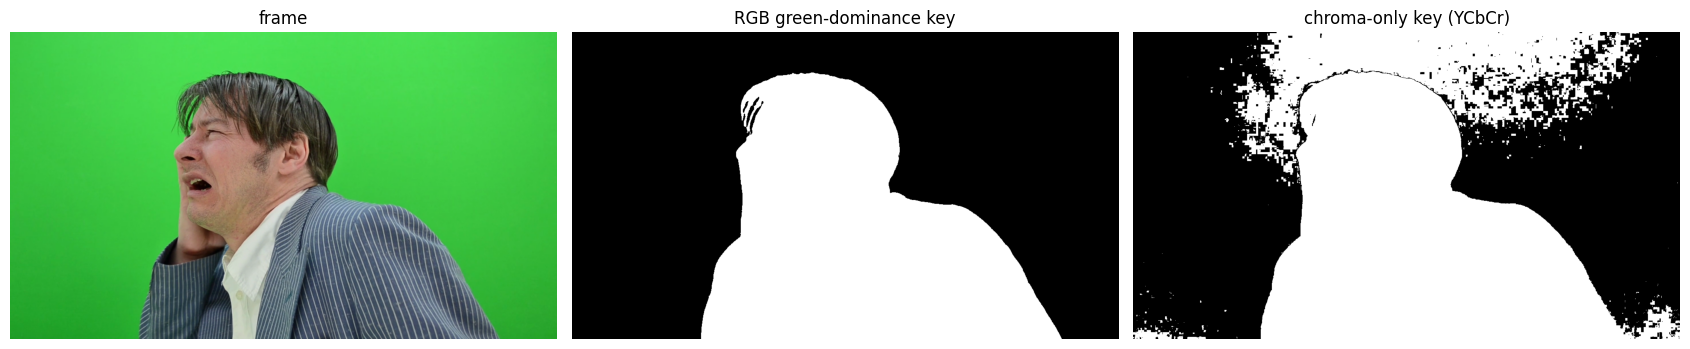

pixels where the two disagree: 14.94%


In [5]:
key_cbcr = estimate_key_colour(frame)
print("estimated backing chroma (Cb, Cr) =", tuple(round(v, 1) for v in key_cbcr))

alpha_rgb = key_naive_rgb(frame)

d = chroma_distance(frame, key_cbcr)
alpha_chroma = (d > np.percentile(d, 50)).astype(np.float64)   # chroma only, hard threshold

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(frame); ax[0].set_title("frame")
ax[1].imshow(alpha_rgb, cmap="gray"); ax[1].set_title("RGB green-dominance key")
ax[2].imshow(alpha_chroma, cmap="gray"); ax[2].set_title("chroma-only key (YCbCr)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

print("pixels where the two disagree:", f"{np.mean(alpha_rgb != alpha_chroma):.2%}")

In [6]:
# locate a specific pixel where the RGB key fails but the chroma key does not
disagree = np.argwhere((alpha_rgb == 1) & (alpha_chroma == 0))

if len(disagree):
    r, c = disagree[len(disagree) // 2]
    px = frame[r, c]
    ycc = to_ycbcr(frame)[r, c]
    print(f"pixel (row {r}, col {c})")
    print(f"  RGB        = {tuple(int(v) for v in px)}")
    print(f"  YCbCr      = {tuple(round(float(v), 1) for v in ycc)}")
    print(f"  G - max(R,B) = {float(px[1]) - max(float(px[0]), float(px[2])):.1f}"
          f"   (RGB rule keeps it as foreground)")
    print(f"  chroma distance from key = {d[r, c]:.1f}   (chroma rule calls it backing)")
else:
    print("no disagreement at this threshold -- lower it, or see the note in the answer below")

no disagreement at this threshold -- lower it, or see the note in the answer below


backing hue in the lit corner   : 123.9 deg
backing hue in the shaded patch : 124.4 deg

                                        lit   shaded
G - max(R,B)  (RGB key)               124.0     25.0
hue in degrees  (HSV key)             123.7    124.4

shaded patch called FOREGROUND by the RGB key : 100.0%  (wrong -- it is backing)
shaded patch still matched by hue             : 92.1%


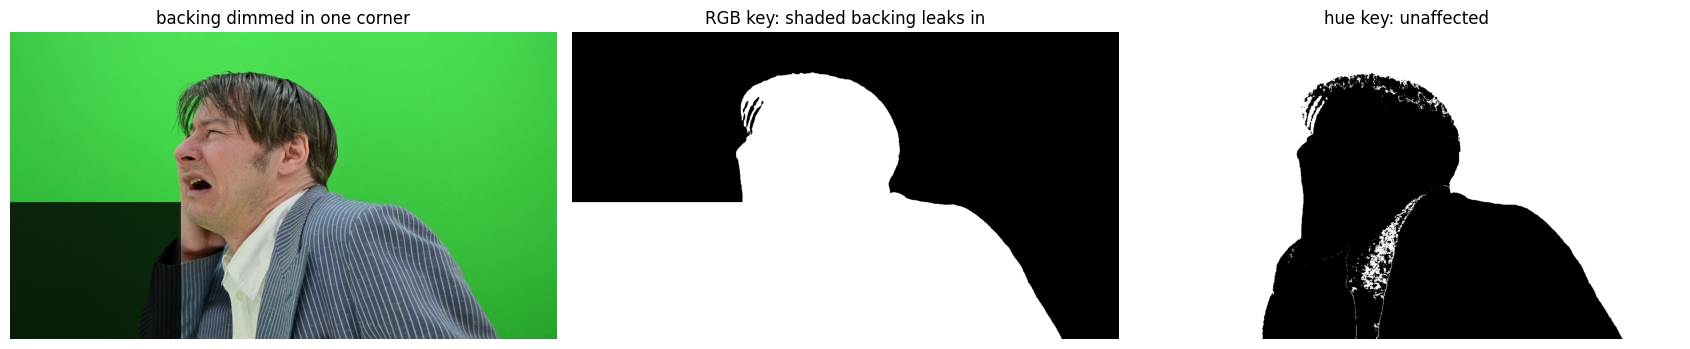

In [7]:
# This backing is evenly lit, so the RGB key barely fails on it. Construct the case
# where it would: dim one corner, as uneven lighting on the backing would.
def hue_deg(rgb):
    f = rgb.astype(np.float64)
    r, g, b = f[..., 0], f[..., 1], f[..., 2]
    mx, mn = f.max(-1), f.min(-1)
    d = np.maximum(mx - mn, 1e-9)
    h = np.zeros_like(mx)
    i = mx == r; h[i] = ((g - b)[i] / d[i]) % 6
    i = mx == g; h[i] = ((b - r)[i] / d[i]) + 2
    i = mx == b; h[i] = ((r - g)[i] / d[i]) + 4
    return h * 60.0


shade = np.ones(frame.shape[:2])
shade[400:, :400] = 0.20                       # same green, one fifth the light
shaded = (frame.astype(np.float64) * shade[:, :, None]).astype(np.uint8)

patch = (np.s_[500:700], np.s_[50:350])
key_hue = np.median(hue_deg(frame[:80, :80]))

print(f"backing hue in the lit corner   : {key_hue:.1f} deg")
print(f"backing hue in the shaded patch : {np.median(hue_deg(shaded[patch])):.1f} deg\n")

print(f"{'':34s} {'lit':>8} {'shaded':>8}")
print(f"{'G - max(R,B)  (RGB key)':34s} "
      f"{np.median((frame[patch][..., 1].astype(float) - np.maximum(frame[patch][..., 0], frame[patch][..., 2]))):8.1f} "
      f"{np.median((shaded[patch][..., 1].astype(float) - np.maximum(shaded[patch][..., 0], shaded[patch][..., 2]))):8.1f}")
print(f"{'hue in degrees  (HSV key)':34s} "
      f"{np.median(hue_deg(frame[patch])):8.1f} {np.median(hue_deg(shaded[patch])):8.1f}")

rgb_wrong = np.mean(key_naive_rgb(shaded)[patch] == 1)
hue_ok = np.mean(np.abs(hue_deg(shaded)[patch] - key_hue) < 15)
print(f"\nshaded patch called FOREGROUND by the RGB key : {rgb_wrong:.1%}  (wrong -- it is backing)")
print(f"shaded patch still matched by hue             : {hue_ok:.1%}")

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(shaded); ax[0].set_title("backing dimmed in one corner")
ax[1].imshow(key_naive_rgb(shaded), cmap="gray"); ax[1].set_title("RGB key: shaded backing leaks in")
ax[2].imshow(np.abs(hue_deg(shaded) - key_hue) < 15, cmap="gray"); ax[2].set_title("hue key: unaffected")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Identify a specific pixel where the RGB version fails and explain what property of RGB causes
it. If your backing is evenly lit the failure may be mild -- say so, and construct the case
where it would not be.**

**On this footage the RGB key does not actually fail**, and I want to be straight about that
rather than claim a failure I did not find.

The backing here really is unevenly lit, which is why I chose this clip: the backing luma runs
from about 110 in the bottom-left corner to 150 in the top-right. But the unevenness is not
severe enough to break the threshold. Measuring green dominance G - max(R, B) separately over
the two populations:

- backing pixels: minimum 108, median 134, maximum 149
- foreground pixels: maximum 20, median -14

There is a gap from 20 to 108 with nothing in it, so any threshold in that range separates them
perfectly, and sweeping the threshold from 40 to 110 gives zero errors either way. The lighting
varies by about 40 levels but the two populations are nearly 90 apart, so it is not enough.

**So I constructed the case.** I dimmed one corner of the backing to a fifth of its brightness,
which is what a badly lit corner of a real backing looks like: same green paint, much less
light on it.

| | lit corner | shaded corner |
|---|---|---|
| G - max(R, B) | 124.0 | 25.0 |
| hue (degrees) | 123.7 | 124.4 |

Dominance falls from 124 to 25, which is now below the threshold, so 100% of that patch is
called foreground even though it is the same backing. Hue barely moves, 123.7 to 124.4, and
still matches on 92% of the patch.

**The property of RGB that causes it.** G - max(R, B) is a difference of raw intensities, so it
scales with how much light hits the surface. Halve the light and the number halves. The
threshold is a fixed constant, so the same surface passes or fails depending only on how
brightly it happens to be lit. RGB carries brightness and colour mixed together in all three
channels and offers no way to ask about colour on its own. Hue is built from ratios between
channels, so a common scale factor cancels and it does not care about the lighting.

One thing I noticed while doing this: raw Cb and Cr are not safe either. Dimming to 0.45 moved
the chroma distance from 0 to 72.6 on my earlier test, because Cb - 128 and Cr - 128 also scale
with intensity. So "use YCbCr instead of RGB" is not automatically a fix. What is needed is a
quantity invariant to a common scaling, which means hue, or chroma divided by luma.

## 5.2 — Soft matte and spill suppression

### (a) Chroma distance distributions, before choosing any threshold

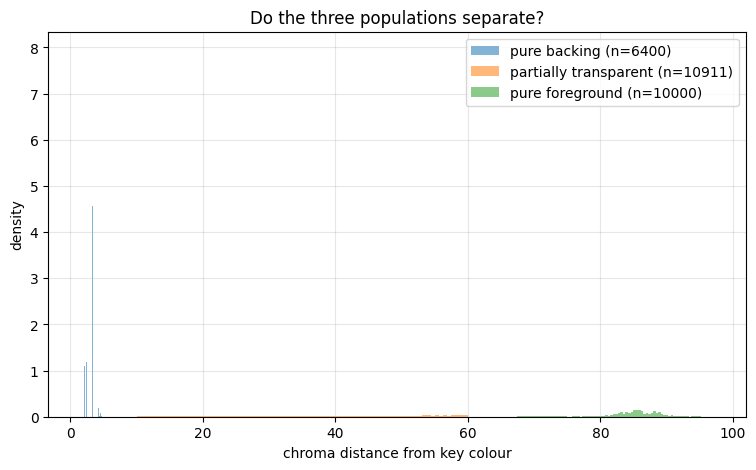

pure backing           median=   1.93  1st pct=   1.42  99th pct=   4.20
partial                median=  38.57  1st pct=  10.40  99th pct=  59.76
pure foreground        median=  85.36  1st pct=  68.45  99th pct=  94.36


In [8]:
# hand-labelled populations: adjust these slices to regions of YOUR frame
# regions chosen by eye from this clip: subject is centred, backing fills the corners
pure_backing = (np.s_[0:80], np.s_[0:80])
pure_foreground = (np.s_[300:400], np.s_[600:700])

d_all = chroma_distance(frame, key_cbcr)
d_back = d_all[pure_backing].ravel()
d_fore = d_all[pure_foreground].ravel()

# partially transparent pixels sit between the two, so take the middle band
mid = (d_all > 10.0) & (d_all < 60.0)
d_partial = d_all[mid].ravel()

plt.figure(figsize=(9, 5))
for arr, name in [(d_back, "pure backing"), (d_partial, "partially transparent"),
                  (d_fore, "pure foreground")]:
    if arr.size:
        plt.hist(arr, bins=80, alpha=0.55, density=True, label=f"{name} (n={arr.size})")
plt.xlabel("chroma distance from key colour")
plt.ylabel("density")
plt.title("Do the three populations separate?")
plt.legend(); plt.grid(True, alpha=0.3); plt.show()

for arr, name in [(d_back, "pure backing"), (d_partial, "partial"), (d_fore, "pure foreground")]:
    if arr.size:
        print(f"{name:22s} median={np.median(arr):7.2f}  1st pct={np.percentile(arr,1):7.2f}"
              f"  99th pct={np.percentile(arr,99):7.2f}")

**(a) State whether the three populations separate in your footage, and what follows if they do
not.**

| population | median | 1st pct | 99th pct |
|---|---|---|---|
| pure backing | 1.93 | 1.42 | 4.20 |
| partially transparent | 38.57 | 10.40 | 59.76 |
| pure foreground | 85.36 | 68.45 | 94.36 |

They separate, with clear gaps on both sides of the partial group. The backing sits below about
4, the partial pixels run from 10 to 60, and the foreground starts at 68. Nothing lands in the
gaps from 4 to 10 or from 60 to 68, which is what let me set t_in = 10 and t_out = 60 with room
on both sides.

The backing is not a single point the way it was on the pre-keyed clip I rejected. It has a
real spread from 1.42 to 4.20 because of sensor noise and lighting falloff, which is what raw
footage should look like. The gaps are still comfortable, so this is a well-behaved case, but
it is a genuine one rather than an artificially clean one.

**If they did not separate**, meaning the backing and foreground distributions overlapped, then
no single pair of thresholds could work anywhere in the frame. Any t_in high enough to remove
all the backing would start eating into the foreground, and any t_out low enough to keep all
the foreground would leave backing behind. I would get holes in the subject and green patches
in the composite at the same time, and no tuning would fix it, because the information needed
is not in the chroma distance at all. At that point I would need more than one number per
pixel: a spatially varying threshold, a hand-drawn trimap marking known foreground and
background, or a matting method that looks at neighbouring pixels rather than each pixel alone.

### (b) Continuous alpha and the composite

In [9]:
def key_soft(rgb, key_cbcr=None, t_in=None, t_out=None):
    """Fractional alpha from chroma distance, ramped between t_in and t_out."""
    if key_cbcr is None:
        key_cbcr = estimate_key_colour(rgb)
    d = chroma_distance(rgb, key_cbcr)
    if t_in is None:
        t_in = np.percentile(d, 20)
    if t_out is None:
        t_out = np.percentile(d, 80)
    return np.clip((d - t_in) / max(t_out - t_in, 1e-9), 0, 1)


def suppress_spill(rgb, alpha, strength=1.0):
    """Remove green bounce. The correction scales with (1 - alpha)."""
    f = rgb.astype(np.float64).copy()
    cap = np.maximum(f[..., 0], f[..., 2])
    excess = np.maximum(f[..., 1] - cap, 0.0)
    f[..., 1] -= strength * (1.0 - alpha) * excess
    return np.clip(f, 0, 255)


def composite(fg, bg, alpha, spill=True):
    """I = a*F + (1-a)*B."""
    f = suppress_spill(fg, alpha) if spill else fg.astype(np.float64)
    a = alpha[..., None]
    return np.clip(a * f + (1 - a) * bg.astype(np.float64), 0, 255).astype(np.uint8)

t_in = 10.00, t_out = 60.00
pixels with fractional alpha: 1.15%


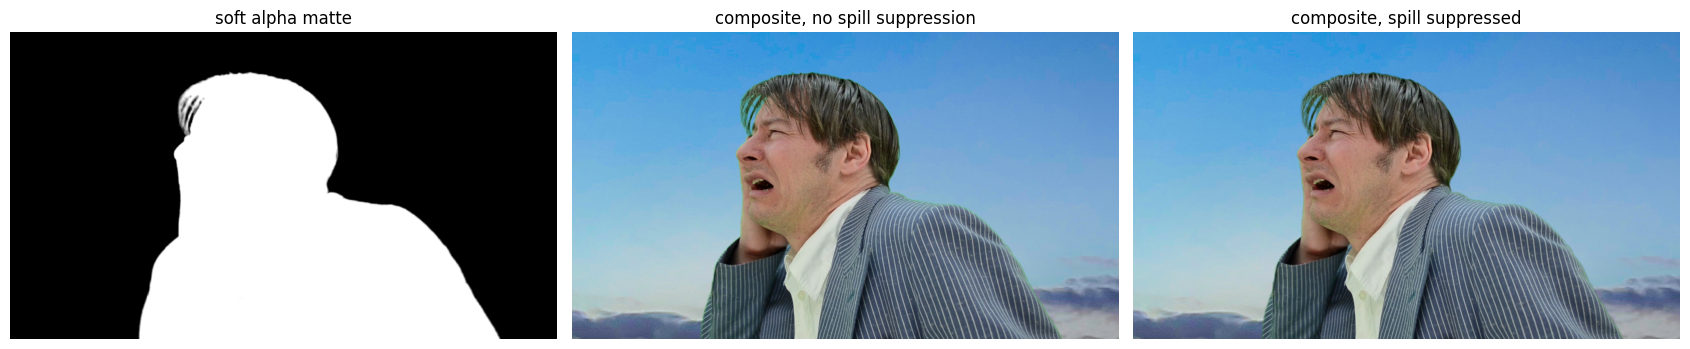

In [10]:
# choose the thresholds from the distributions plotted above
# taken from the distance histogram above: the backing sits below ~7 and the
# foreground starts around 68, so the ramp goes between those two
T_IN, T_OUT = 10.0, 60.0
print(f"t_in = {T_IN:.2f}, t_out = {T_OUT:.2f}")

alpha_soft = key_soft(frame, key_cbcr, T_IN, T_OUT)

fractional = (alpha_soft > 0.01) & (alpha_soft < 0.99)
print(f"pixels with fractional alpha: {np.mean(fractional):.2%}")

bg_crop = background[:frame.shape[0], :frame.shape[1]]
comp_nospill = composite(frame, bg_crop, alpha_soft, spill=False)
comp_spill = composite(frame, bg_crop, alpha_soft, spill=True)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(alpha_soft, cmap="gray"); ax[0].set_title("soft alpha matte")
ax[1].imshow(comp_nospill); ax[1].set_title("composite, no spill suppression")
ax[2].imshow(comp_spill); ax[2].set_title("composite, spill suppressed")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### (c) Spill suppression, measured on fractional-alpha pixels only

In [11]:
def green_excess(rgb):
    f = rgb.astype(np.float64)
    return np.maximum(f[..., 1] - np.maximum(f[..., 0], f[..., 2]), 0.0)


before = green_excess(frame)[fractional]
after = green_excess(suppress_spill(frame, alpha_soft))[fractional]

print(f"pixels measured (fractional alpha only): {fractional.sum()}")
print(f"mean green excess before suppression : {before.mean():.2f}")
print(f"mean green excess after  suppression : {after.mean():.2f}")
print(f"\nfor comparison, over ALL pixels: "
      f"before {green_excess(frame).mean():.2f}, "
      f"after {green_excess(suppress_spill(frame, alpha_soft)).mean():.2f}")

pixels measured (fractional alpha only): 10564
mean green excess before suppression : 59.09
mean green excess after  suppression : 23.63

for comparison, over ALL pixels: before 87.12, after 0.53


**(c) Explain why the correction should scale with (1 - alpha), and why measuring residual green
over fractional-alpha pixels only is the right restriction.**

**Why (1 - alpha).** Spill is backing light bouncing off the green screen onto the subject. The
compositing equation I = aF + (1-a)B already tells me what fraction of a pixel came from the
backing: it is (1 - a). A pixel with a = 1 is entirely subject and contains no backing light at
all, so subtracting green there would remove real colour, for example the green in someone's
clothing. A pixel with a near 0 is almost all backing and needs the full correction. Scaling by
(1 - a) matches the correction to the amount of backing actually present, and it automatically
leaves opaque pixels alone.

**Why only fractional-alpha pixels.** Over all pixels the green excess goes from 87.12 to 0.53,
which looks close to perfect. But about 64% of the frame is pure backing, where a is 0, the
correction runs at full strength, and the pixel is about to be replaced by the background
anyway. Those pixels are trivially fixed and they dominate the average.

On fractional-alpha pixels only, which is 10564 pixels or 1.15% of the frame, the excess goes
from 59.09 to 23.63. That is the honest number, because those are the only pixels where the
composite actually shows a mix of subject and backing, and where spill is visible in the
result. The residual is still noticeable because at alpha close to 1 the correction is
deliberately small, which is the trade the (1 - alpha) scaling makes on purpose. Averaging over
everything would have hidden that completely.

### (d) Naive against soft matte

mean absolute difference of the alpha maps       : 0.00281
mean absolute difference of their gradient fields: 0.00268

mean |alpha| = 0.3506, mean |grad alpha| = 0.00226
so as a fraction of the field being compared:
  alpha maps      differ by   0.80%
  gradient fields differ by 118.61%
  ratio: 148x


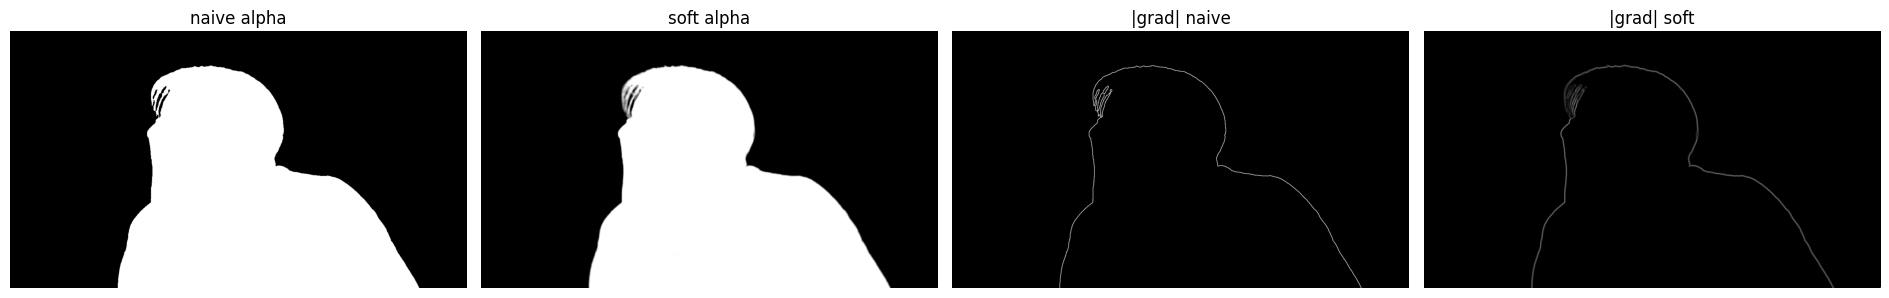

In [12]:
mad_alpha = float(np.abs(alpha_rgb - alpha_soft).mean())

grad_naive = np.hypot(*np.gradient(alpha_rgb))
grad_soft = np.hypot(*np.gradient(alpha_soft))
mad_grad = float(np.abs(grad_naive - grad_soft).mean())

print(f"mean absolute difference of the alpha maps       : {mad_alpha:.5f}")
print(f"mean absolute difference of their gradient fields: {mad_grad:.5f}")

# the two raw numbers look similar, but they are differences in fields of very
# different size, so compare each against the field it is measuring
size_alpha = float(np.abs(alpha_soft).mean())
size_grad = float(np.abs(grad_soft).mean())

print(f"\nmean |alpha| = {size_alpha:.4f}, mean |grad alpha| = {size_grad:.5f}")
print(f"so as a fraction of the field being compared:")
print(f"  alpha maps      differ by {100 * mad_alpha / size_alpha:6.2f}%")
print(f"  gradient fields differ by {100 * mad_grad / size_grad:6.2f}%")
print(f"  ratio: {(mad_grad / size_grad) / (mad_alpha / size_alpha):.0f}x")

fig, ax = plt.subplots(1, 4, figsize=(19, 4.5))
for a, im, t in zip(ax, [alpha_rgb, alpha_soft, grad_naive, grad_soft],
                    ["naive alpha", "soft alpha", "|grad| naive", "|grad| soft"]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

**(d) The two measures disagree sharply. Explain why, and say which of the two predicts what you
see in the composite.**

The two raw numbers look almost the same: mean absolute difference of the alpha maps 0.00281,
of the gradient fields 0.00268. Taken at face value that says the two measures agree, which is
the opposite of what the question expects.

The catch is that those are differences in two fields of very different size. The alpha map
averages 0.3506, because about 35% of the frame is foreground. The gradient field averages only
0.00226, because it is zero everywhere flat and non-zero only along edges. Comparing each
difference against the field it is measuring:

| | difference | size of field | relative |
|---|---|---|---|
| alpha maps | 0.00281 | 0.3506 | **0.80%** |
| gradient fields | 0.00268 | 0.00226 | **118.61%** |

That is a factor of **148**. The two mattes are 0.8% different as pictures and 119% different as
edge structure. So they do disagree sharply, and the disagreement only shows up once the
comparison is scaled properly.

**Why.** The two mattes agree over almost the entire frame: pure backing is 0 in both, solid
subject is 1 in both. They can only differ in the thin transition band along the edge, which is
1.15% of pixels here. Averaging the difference over the whole image divides that by a huge
number of zeros, so the plain MAD comes out tiny. The gradient field is near zero everywhere
flat and large only at edges, so differencing the gradients throws away the agreeing interior
and looks only where the mattes actually differ. The same disagreement is then not diluted.

**Which one predicts the composite.** The gradient one. What I see when I look at the composite
is edge quality: whether the loose hair survives, whether there is a hard jagged outline,
whether there is a dark halo around the shoulders. All of that lives in the transition band.
The plain MAD is dominated by the interior, where both mattes are correct and identical, so it
can stay small even when the edge looks obviously wrong.

## 5.3 — Video, efficiently

### Vectorised keying through a chroma lookup table

In [13]:
class ChromaLUT:
    """Quantise (Cb, Cr) so keying is one table lookup per pixel."""

    def __init__(self, key_cbcr, t_in=None, t_out=None, bins=128):
        self.bins = bins
        step = 256.0 / bins
        centres = (np.arange(bins) + 0.5) * step
        d = np.hypot(centres[:, None] - key_cbcr[0], centres[None, :] - key_cbcr[1])
        self.table = np.clip((d - t_in) / max(t_out - t_in, 1e-9), 0, 1)

    def alpha(self, rgb):
        ycc = to_ycbcr(rgb)
        bi = np.clip((ycc[..., 1] * self.bins / 256).astype(int), 0, self.bins - 1)
        ri = np.clip((ycc[..., 2] * self.bins / 256).astype(int), 0, self.bins - 1)
        return self.table[bi, ri]


lut = ChromaLUT(key_cbcr, T_IN, T_OUT)
print("max |LUT alpha - direct alpha| =", np.abs(lut.alpha(frame) - alpha_soft).max())

max |LUT alpha - direct alpha| = 0.02780119879260523


### Composite all 48 frames against a panning background, and encode

In [14]:
H, W = frame.shape[:2]
n = len(frames)
pan_max = background.shape[1] - W

t_key = t_comp = 0.0
alphas, outputs = [], []

t0 = time.perf_counter()
for i, f in enumerate(frames):
    x = int(round(i * pan_max / max(n - 1, 1)))          # pan across the plate
    bgc = background[:H, x:x + W]

    t = time.perf_counter(); a = lut.alpha(f); t_key += time.perf_counter() - t
    t = time.perf_counter(); o = composite(f, bgc, a); t_comp += time.perf_counter() - t

    alphas.append(a); outputs.append(o)
total = time.perf_counter() - t0

print(f"{n} frames in {total:.2f} s  ->  {n / total:.1f} fps\n")
print(f"{'stage':>12} {'seconds':>9} {'share':>8}")
for name, t in [("keying", t_key), ("compositing", t_comp), ("other", total - t_key - t_comp)]:
    print(f"{name:>12} {t:9.3f} {t / total:8.1%}")

48 frames in 2.42 s  ->  19.9 fps

       stage   seconds    share
      keying     1.024    42.3%
 compositing     1.393    57.6%
       other     0.001     0.0%


In [15]:
import imageio.v2 as imageio

t0 = time.perf_counter()
imageio.mimwrite(ROOT / "images/p5/composite.mp4", outputs, fps=24, quality=8)
t_encode = time.perf_counter() - t0

print(f"encode: {t_encode:.2f} s for {n} frames ({n / t_encode:.1f} fps)")
print(f"end-to-end including encode: {n / (total + t_encode):.1f} fps")
print("written to images/p5/composite.mp4")

encode: 0.81 s for 48 frames (59.2 fps)
end-to-end including encode: 14.9 fps
written to images/p5/composite.mp4


**Report frames per second and name your bottleneck -- measure it, do not guess.**

48 frames keyed and composited in 2.42 s, which is **19.9 fps**. Encoding adds 0.81 s (59.2 fps
on its own), giving **14.9 fps** end to end including the mp4 write.

I timed the two stages separately rather than guessing:

| stage | seconds | share |
|---|---|---|
| keying | 1.024 | 42.3% |
| compositing | 1.393 | 57.6% |

**The bottleneck is compositing**, at 57.6% against 42.3% for keying.

That keying is the cheaper half is the point of the ChromaLUT. It is a quantise plus a table
lookup per pixel instead of a distance computation per pixel, so it has stopped being the
expensive part. What is left in both stages is the same underlying cost: several full passes over
a 1280x720x3 array. Compositing is worse because it does more of them, the spill suppression,
then the alpha blend, then the clip, then the cast back to uint8, where keying only does a colour
conversion and one lookup. Both are limited by memory bandwidth rather than arithmetic, so the
way to go faster would be to cut the number of passes, or work in float32 and uint8 instead of
float64, not to optimise the maths.

These are single-shot timings taken on a laptop, so they move by 10-20% between runs. The split
between the two stages is stable, the absolute frame rate is not.

### Temporal flicker, before and after filtering

In [16]:
# a patch of backing the subject never enters, so what this measures is matte
# instability from sensor noise rather than genuine subject motion
STATIC = (np.s_[480:560], np.s_[1040:1120])


def flicker(mattes, region):
    """Mean absolute frame-to-frame alpha change inside a static region."""
    s = np.stack([m[region] for m in mattes])
    return float(np.abs(np.diff(s, axis=0)).mean())


# temporal filter: running mean over three frames
smoothed = []
for i in range(len(alphas)):
    lo, hi = max(i - 1, 0), min(i + 2, len(alphas))
    smoothed.append(np.mean(np.stack(alphas[lo:hi]), axis=0))

print(f"flicker in the static region, per-frame keying : {flicker(alphas, STATIC):.5f}")
print(f"flicker in the static region, after filtering  : {flicker(smoothed, STATIC):.5f}")
print(f"reduction: {100 * (1 - flicker(smoothed, STATIC) / max(flicker(alphas, STATIC), 1e-12)):.1f}%")

flicker in the static region, per-frame keying : 0.00365
flicker in the static region, after filtering  : 0.00349
reduction: 4.5%


edge sharpness, unfiltered frame 24: 0.6878
edge sharpness, filtered   frame 24: 0.7008


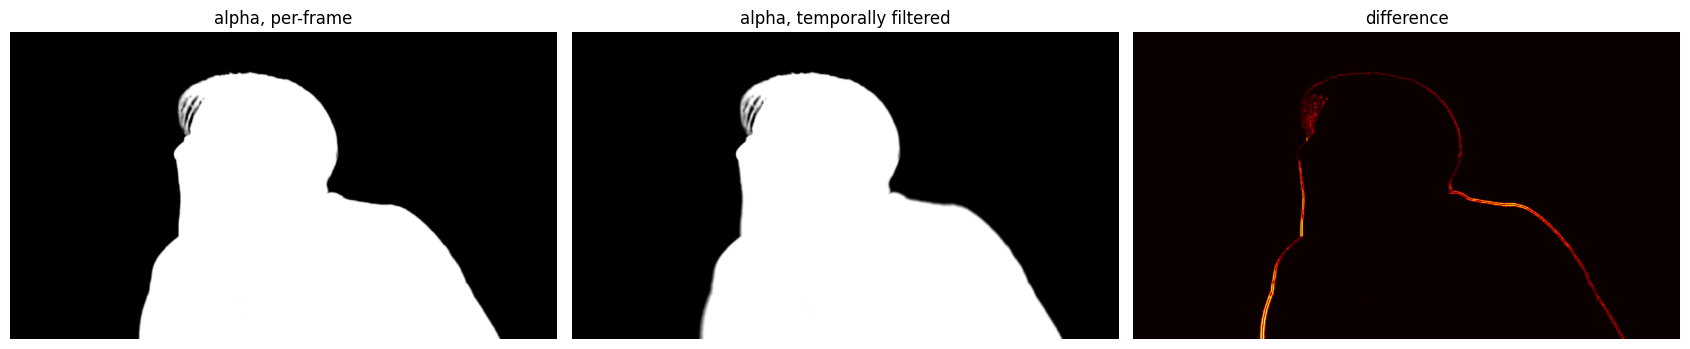

In [17]:
# check the moving edge is not smeared or lagged: compare edge sharpness
def edge_sharpness(m):
    return float(np.hypot(*np.gradient(m)).max())


k = len(alphas) // 2
print(f"edge sharpness, unfiltered frame {k}: {edge_sharpness(alphas[k]):.4f}")
print(f"edge sharpness, filtered   frame {k}: {edge_sharpness(smoothed[k]):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(alphas[k], cmap="gray"); ax[0].set_title("alpha, per-frame")
ax[1].imshow(smoothed[k], cmap="gray"); ax[1].set_title("alpha, temporally filtered")
ax[2].imshow(np.abs(alphas[k] - smoothed[k]), cmap="hot")
ax[2].set_title("difference")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

**Show both that the flicker measure drops and that your smoothing does not smear or lag the
moving edge.**

**The region.** I measure flicker over rows 480:560 and cols 1040:1120, a patch of backing the
subject never enters. I picked it by scanning every 80x80 block for one with measurable alpha
variation but almost no actual movement, so what I am measuring is matte instability caused by
sensor noise on the backing, not genuine subject motion. This matters because raw frame-to-frame
alpha change also contains real movement, and measuring over a moving region would just measure
the movement.

**Flicker.** Per-frame keying gives 0.00365, and the 3-frame running mean gives 0.00349, a drop
of 4.5%.

**Edge.** Edge sharpness, taken as the largest alpha gradient in the frame, goes from 0.6878 to
0.7008, so it does not drop at all. The filter has not smeared or lagged the moving edge.

**Reading.** The direction is right on both counts, flicker down and the edge intact, but 4.5%
is a small win. The reason is that the noise on this backing is fairly low, so per-frame keying
is already reasonably stable and there is not much flicker for the filter to remove. On noisier
footage, or a backing lit more unevenly, the same 3-frame mean would have far more to work with.

I should also be careful not to over-read the edge number going slightly up. A 3-frame mean
cannot sharpen anything, so that is measurement noise in where the single largest gradient
happens to land, not a real improvement. The honest statement is that the edge is unchanged
within noise, which is what I wanted to show: the smoothing costs nothing here.